# 전이 학습(transfer learning)

<img src = "./image/pytorch_img/transfer_learning.png">

- 일반적으로 합성곱 신경망 기반의 딥러닝 모델을 제대로 훈련시키려면 많은 양의 데이터가 필요함

- 하지만 큰 데이터셋을 확보하고 훈련시키는 데에 많은 돈과 시간이 필요

- 이러한 문제를 해결하기 위해 전이 학습을 이용

- 전이 학습
    - 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 문제에 맞게 보정해서 사용하는 것
        - 이 때 아주 큰 데이터셋을 사용하여 훈련된 모델을 사전 학습 모델(사전 훈련된 모델)이라고 함
    - 전이 학습을 이용하면 비교적 적은 수의 데이터를 가지고도 원하는 과제를 해결할 수 있음

## 특성 추출 기법(feature extractor)

<img src = "./image/pytorch_img/feature_extractor.jpg">

- 사전 학습 모델을 가져온 후 완전연결층 부분만 새로 만듦

- 학습할 때는 완전연결층만 학습하고 나머지 계층은 학습되지 않도록 함
    - 데이터 분류기(완전연결층) : 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분
 
- 자주 사용되는 이미지 분류 사전학습 모델
    - Xception
    - Inception V3
    - ResNet50
    - VGG19
    - MobileNet

In [1]:
import os
import time
import glob
import numpy as np

import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

## 데이터 증강

In [2]:
data_path = "./data/catanddog/train"

transform = transforms.Compose(
    [
        transforms.Resize([256, 256]),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
    ]
)

train_dataset = torchvision.datasets.ImageFolder(
    data_path,
    transform = transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size = 32,
    num_workers = 8,
    shuffle = True
)

print(len(train_dataset))

385


In [3]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

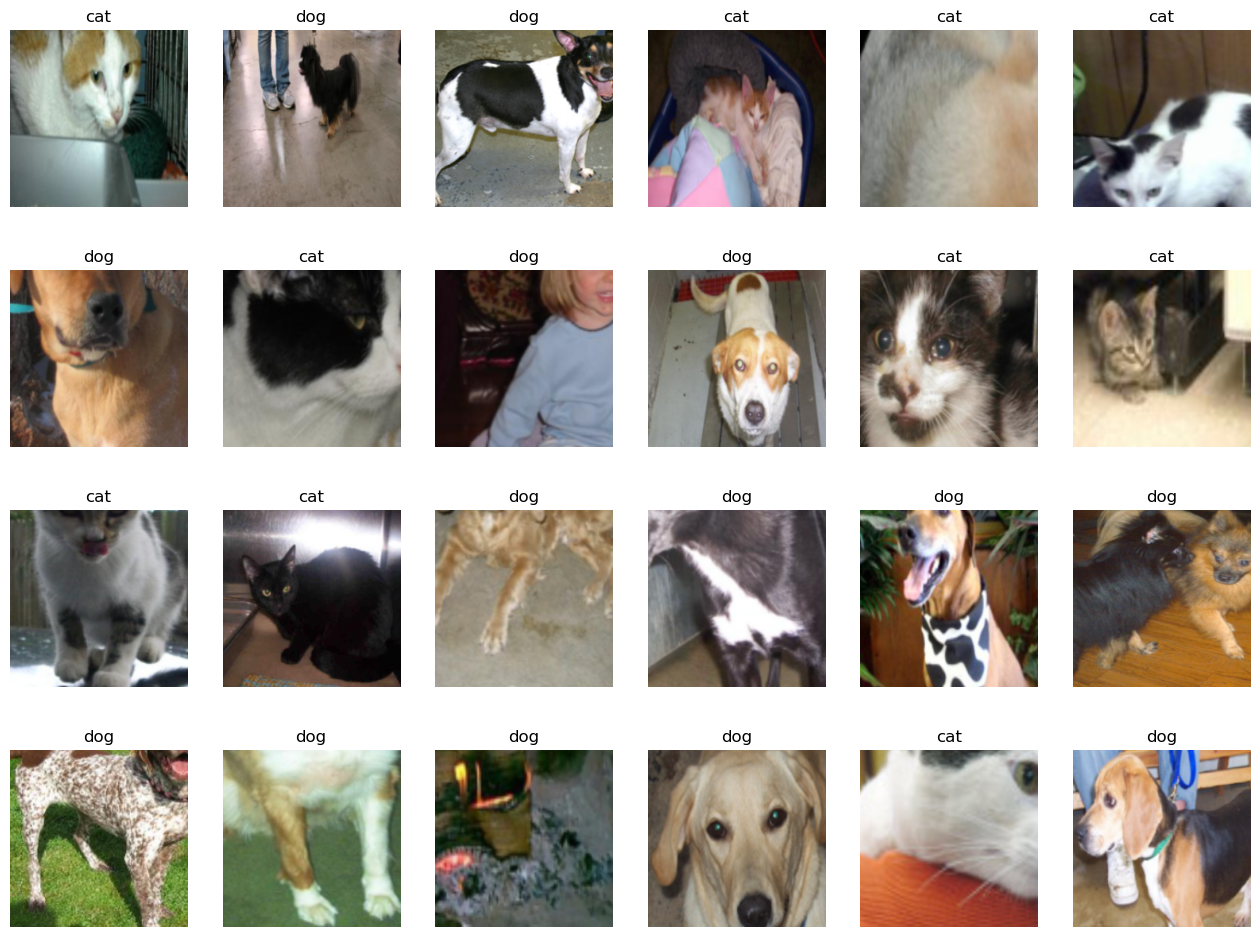

In [4]:
# 학습에 사용될 이미지 출력
samples, labels = next(iter(train_loader)) # train_loader에서 데이터를 하나씩 꺼내 오기

classes = ({0 : "cat", 1 : "dog"})

fig = plt.figure(figsize = (16, 24))

for i in range(24):
    a = fig.add_subplot(4, 6, i + 1)
    a.set_title(classes[labels[i].item()])
    a.axis("off")
    a.imshow(np.transpose(samples[i].numpy(), (1, 2, 0))) # 3, 224, 224 크기를 224, 224, 3 으로 변환

plt.subplots_adjust(bottom = 0.2, top = 0.6, hspace = 0)

In [5]:
samples.shape

torch.Size([32, 3, 224, 224])

In [6]:
np.transpose(samples[0].numpy(), (1, 2, 0)).shape

(224, 224, 3)

# 사전학습 모델 준비

In [7]:
resnet18 = models.resnet18(pretrained = True) # pretrained = True : 사전 학습된 가중치를 사용

C:\ProgramData\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


## ResNet18

- ImageNet 데이터베이스의 100만개가 넘는 영상을 이용하여 훈련된 신경망

- 입력 제약이 매우 크고 충분한 메모리(RAM)이 없으면 학습 속도가 느려지는 단점이 있음

In [8]:
# ResNet18이 파라미터 학습을 하지 않도록 고정
for param in resnet18.parameters():
    param.requires_grad = False # 역전파 중 파라미터들에 대한 변화를 계산할 필요 없음

## 완전연결층 추가

In [9]:
resnet18

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [11]:
resnet18.fc = nn.Linear(512, 2) # 클래스가 2개

In [12]:
# 모델 파라미터 값 확인
for name, param in resnet18.named_parameters():
    if param.requires_grad:
        print(name, param.data)

fc.weight tensor([[ 0.0050,  0.0350,  0.0019,  ..., -0.0090,  0.0045, -0.0307],
        [-0.0040,  0.0347, -0.0146,  ...,  0.0368,  0.0052, -0.0225]])
fc.bias tensor([0.0026, 0.0150])


In [13]:
resnet18

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

# 모델 학습

In [15]:
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs = 13, is_train = True):
    '''
    파라미터 : (모델, 학습데이터, 손실함수, 옵티마이저, 장치)
    '''
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch}/{num_epochs - 1}")
        print("-" * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            # 출력 결과와 레이블의 오차를 계산한 결과를 누적하여 저장
            running_loss += loss.item() * inputs.size(0) 
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print(f"Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join("./data/catanddog/", f"{epoch:0=2d}.pth"))
        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {(time_elapsed // 60):.0f}m {(time_elapsed % 60):.0f}s")
    print(f"Best Acc: {best_acc:4f}")

    return acc_history, loss_history

In [17]:
params_to_update = []

for name, param in resnet18.named_parameters():
    if param.requires_grad:
        params_to_update.append(param)
        print(name)

optimizer = optim.Adam(params_to_update)

fc.weight
fc.bias


In [18]:
params_to_update

[Parameter containing:
 tensor([[ 0.0050,  0.0350,  0.0019,  ..., -0.0090,  0.0045, -0.0307],
         [-0.0040,  0.0347, -0.0146,  ...,  0.0368,  0.0052, -0.0225]],
        requires_grad=True),
 Parameter containing:
 tensor([0.0026, 0.0150], requires_grad=True)]

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion, optimizer, device)

Epoch 0/12
----------
Loss: 0.5152 Acc: 0.7688

Epoch 1/12
----------
Loss: 0.3675 Acc: 0.8416

Epoch 2/12
----------
Loss: 0.2990 Acc: 0.8857

Epoch 3/12
----------
Loss: 0.2678 Acc: 0.8779

Epoch 4/12
----------
Loss: 0.2688 Acc: 0.8883

Epoch 5/12
----------
Loss: 0.2500 Acc: 0.8883

Epoch 6/12
----------
Loss: 0.2598 Acc: 0.8727

Epoch 7/12
----------
Loss: 0.3091 Acc: 0.8545

Epoch 8/12
----------
Loss: 0.3595 Acc: 0.8416

Epoch 9/12
----------
Loss: 0.2146 Acc: 0.9039

Epoch 10/12
----------
Loss: 0.2318 Acc: 0.8935

Epoch 11/12
----------
Loss: 0.2506 Acc: 0.8831

Epoch 12/12
----------
Loss: 0.2488 Acc: 0.8675

Training complete in 4m 40s
Best Acc: 0.903896


# 테스트 데이터 평가

In [22]:
test_path = "./data/catanddog/test"

transform = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
    ]
)

test_dataset = torchvision.datasets.ImageFolder(
    root = test_path,
    transform = transform
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size = 32,
    num_workers = 1,
    shuffle = True
)

print(len(test_dataset))

98


In [24]:
def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    # 경로에서 pth 확장자를 갖는 파일을 가져오기
    saved_models = glob.glob("./data/catanddog/" + "*.pth") 
    saved_models.sort()
    print("saved_model", saved_models)

    for model_path in saved_models:
        print("Loading model", model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad():
                outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            preds[preds >= 0.5] = 1
            preds[preds < 0.5] = 0
            running_corrects += preds.cpu().eq(labels.cpu()).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset)
        print(f"Acc: {epoch_acc:.4f}")

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print(f"Validation complete in {(time_elapsed // 60):.0f}m {(time_elapsed % 60):.0f}s")
    print(f"Best Acc: {best_acc:4f}")

    return acc_history

In [25]:
# 테스트 데이터를 평가 함수에 적용
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['./data/catanddog\\00.pth', './data/catanddog\\01.pth', './data/catanddog\\02.pth', './data/catanddog\\03.pth', './data/catanddog\\04.pth', './data/catanddog\\05.pth', './data/catanddog\\06.pth', './data/catanddog\\07.pth', './data/catanddog\\08.pth', './data/catanddog\\09.pth', './data/catanddog\\10.pth', './data/catanddog\\11.pth', './data/catanddog\\12.pth']
Loading model ./data/catanddog\00.pth


C:\Users\[REDACTED]\AppData\Local\Temp\ipykernel_12364\2439732649.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))


Acc: 0.8980

Loading model ./data/catanddog\01.pth
Acc: 0.8673

Loading model ./data/catanddog\02.pth
Acc: 0.9388

Loading model ./data/catanddog\03.pth
Acc: 0.9286

Loading model ./data/catanddog\04.pth
Acc: 0.9388

Loading model ./data/catanddog\05.pth
Acc: 0.9388

Loading model ./data/catanddog\06.pth
Acc: 0.9490

Loading model ./data/catanddog\07.pth
Acc: 0.9490

Loading model ./data/catanddog\08.pth
Acc: 0.8776

Loading model ./data/catanddog\09.pth
Acc: 0.8980

Loading model ./data/catanddog\10.pth
Acc: 0.9286

Loading model ./data/catanddog\11.pth
Acc: 0.9388

Loading model ./data/catanddog\12.pth
Acc: 0.9286

Validation complete in 1m 23s
Best Acc: 0.948980


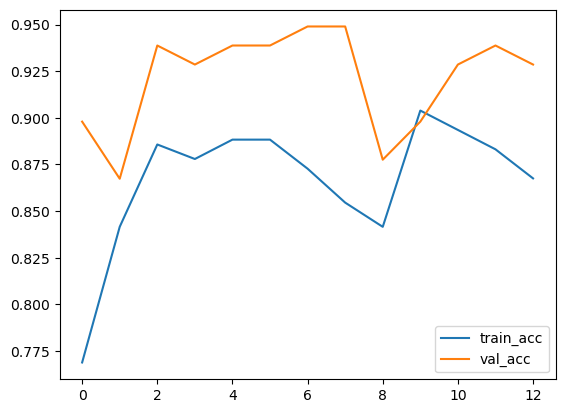

In [26]:
plt.plot(train_acc_hist, label = "train_acc")
plt.plot(val_acc_hist, label = "val_acc")
plt.legend()
plt.show()

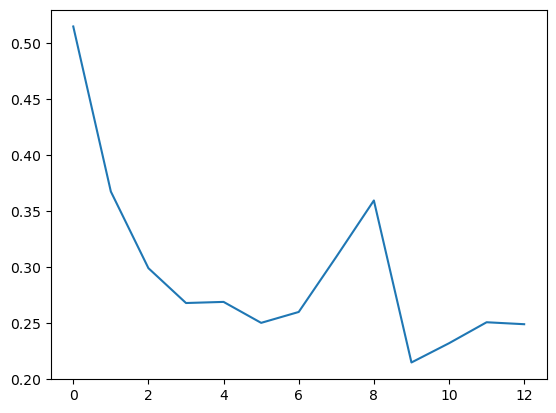

In [27]:
plt.plot(train_loss_hist)
plt.show()

# 예측 이미지 출력

In [30]:
def im_convert(tensor):
    image = tensor.clone().detach().numpy() # 기존 텐서의 내용을 복사한 텐서를 생성
    image = image.transpose(1, 2, 0)
    image = image.clip(0, 1) # 값을 특정 범위로 제한
    return image    

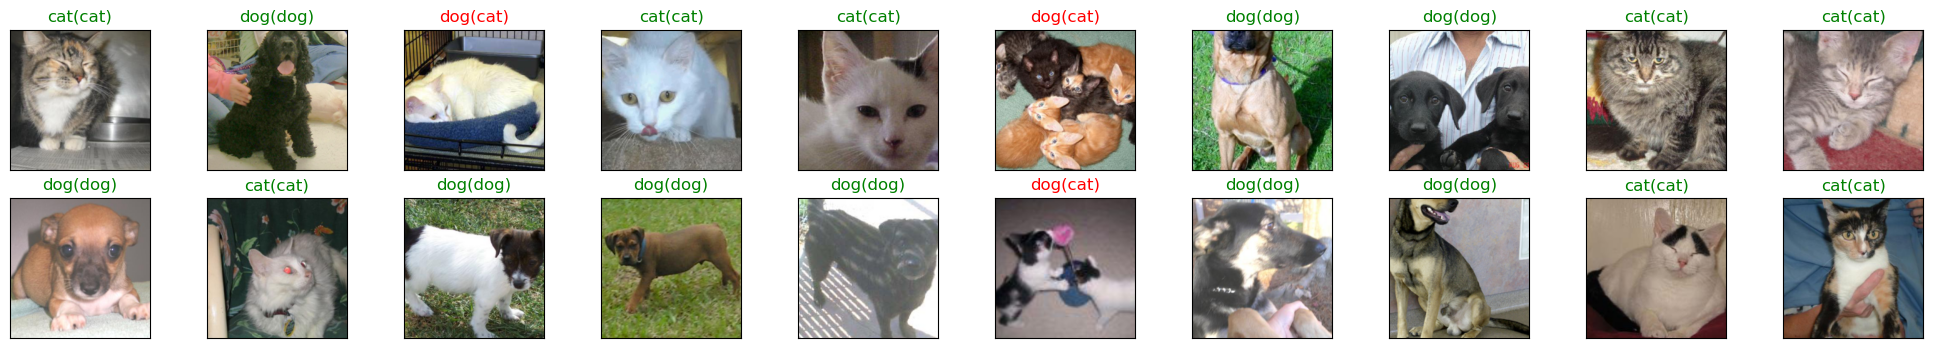

In [31]:
classes = {0 : "cat", 1 : "dog"}

dataiter = iter(test_loader)
images, labels = next(dataiter)
output = resnet18(images.to(device))
_, preds = torch.max(output, 1)

fig = plt.figure(figsize = (25, 4))

for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx + 1, xticks = [], yticks = [])
    plt.imshow(im_convert(images[idx]))
    a.set_title(classes[labels[i].item()])
    ax.set_title(f"{str(classes[preds[idx].item()])}({str(classes[labels[idx].item()])})",
                 color = ("green" if preds[idx] == labels[idx] else "red"))
plt.show()